# Exploratory Data Analytics

## 1.1Distribution of target variable (histogram + box plot)

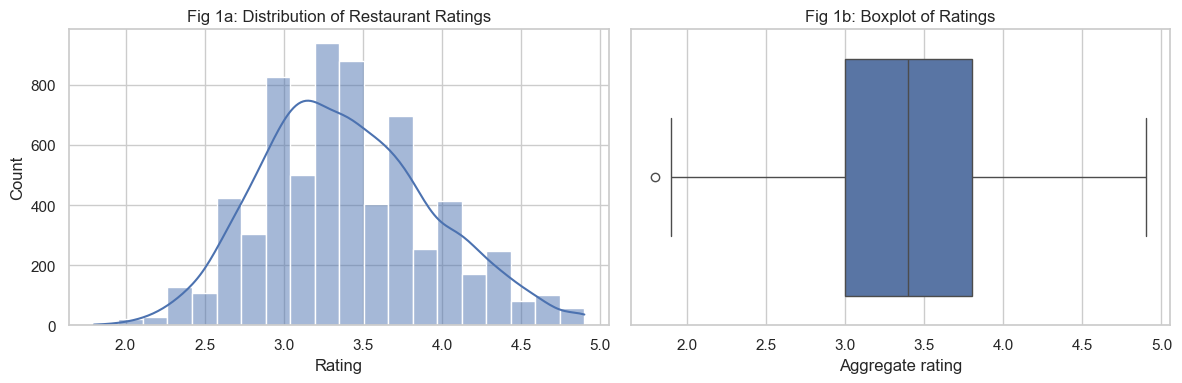

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

df = pd.read_csv('zomato_clean_all.csv')


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,4))
sns.histplot(df['Aggregate rating'], bins=20, kde=True, ax=ax1)
ax1.set_title('Fig 1a: Distribution of Restaurant Ratings')
ax1.set_xlabel('Rating')
sns.boxplot(x=df['Aggregate rating'], ax=ax2)
ax2.set_title('Fig 1b: Boxplot of Ratings')
plt.tight_layout()
plt.show()

The ratings are concentrated between 3.0 and 4.5, with very few below 2.0, indicating that most restaurants have mid-to-high ratings.

There is a left skew (very few low ratings), so attention should be paid to the imbalance issue when modeling (if doing classification).

The box plot shows some unusually low ratings (<2.0), but their number is small; they can either be retained or capped.

## 1.2Univariate – Frequency of price range (Price range)

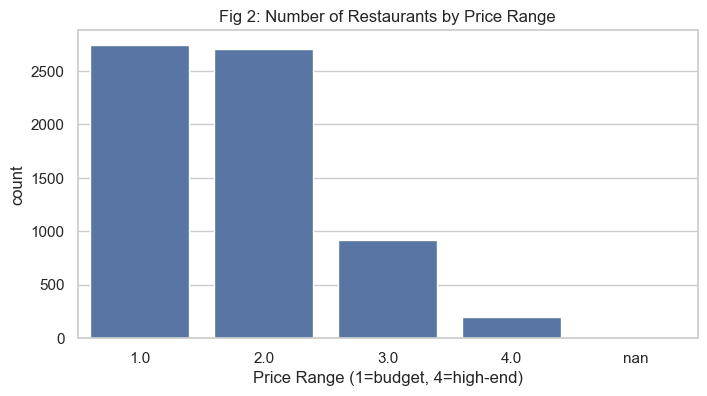

In [6]:
plt.figure(figsize=(8,4))
sns.countplot(data=df, x='Price range', order=sorted(df['Price range'].unique()))
plt.title('Fig 2: Number of Restaurants by Price Range')
plt.xlabel('Price Range (1=budget, 4=high-end)')
plt.show()

Most restaurants are concentrated in price range 2–3, indicating that mid-range restaurants dominate.
The number of restaurants in price range 4 (high-end) is relatively small, so category merging or the use of weights may be needed during modeling.

## 2.1Bivariate – Price vs Rating (scatter plot + regression line)

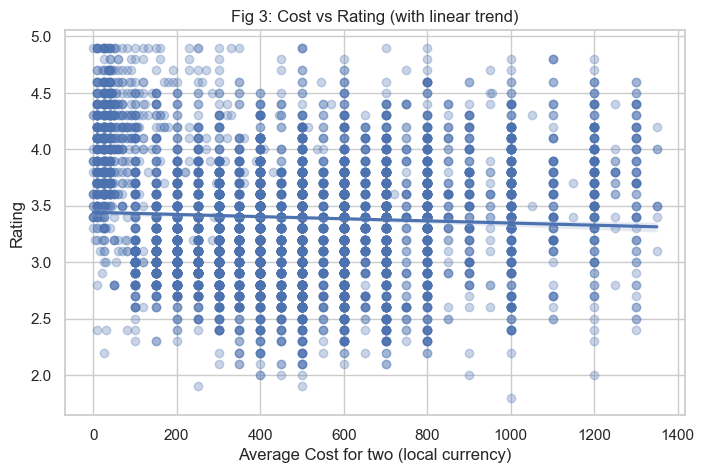

In [7]:
plt.figure(figsize=(8,5))
sns.regplot(data=df, x='Average Cost for two', y='Aggregate rating', scatter_kws={'alpha':0.3})
plt.title('Fig 3: Cost vs Rating (with linear trend)')
plt.xlabel('Average Cost for two (local currency)')
plt.ylabel('Rating')
plt.show()

Overall trend: There is a weak positive correlation between price and rating (r ≈ 0.2–0.3), but a high price does not guarantee a high rating.
There are many restaurants with low prices (<500) but very high ratings. Implication: The linear relationship is weak; segmentation or interaction terms may be needed.

## 2.2Bivariate – Online delivery availability vs Rating (violin plot)

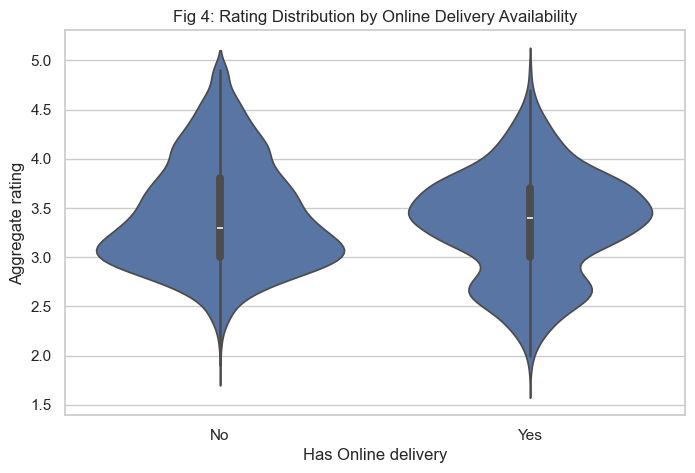

In [8]:
plt.figure(figsize=(8,5))
sns.violinplot(data=df, x='Has Online delivery', y='Aggregate rating')
plt.title('Fig 4: Rating Distribution by Online Delivery Availability')
plt.xticks([0,1], ['No', 'Yes'])
plt.show()

Restaurants that offer online delivery have a slightly higher median rating (approximately 3.7 vs 3.4).
However, both groups show wide distributions, indicating that online delivery is only one of many influencing factors, and other features need to be considered in combination.

## 2.3The impact of 'reservable' on ratings (violin plot)

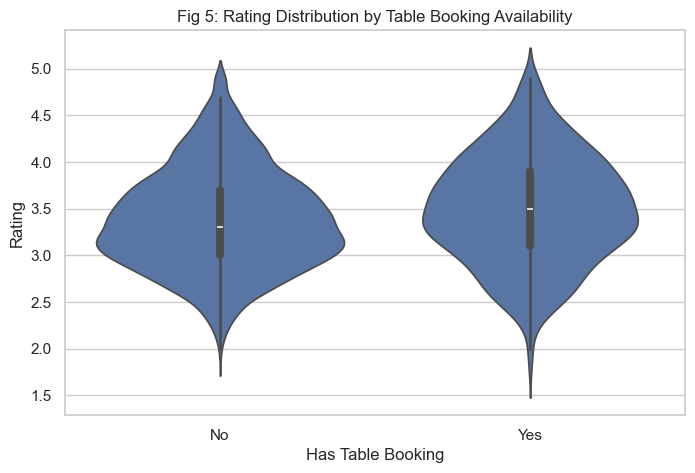

In [16]:
plt.figure(figsize=(8,5))
sns.violinplot(data=df, x='Has Table booking', y='Aggregate rating')
plt.title('Fig 5: Rating Distribution by Table Booking Availability')
plt.xticks([0,1], ['No', 'Yes'])
plt.xlabel('Has Table Booking')
plt.ylabel('Rating')
plt.show()

## 2.4Bivariate – Number of restaurant votes vs Rating (scatter plot, log-transformed)

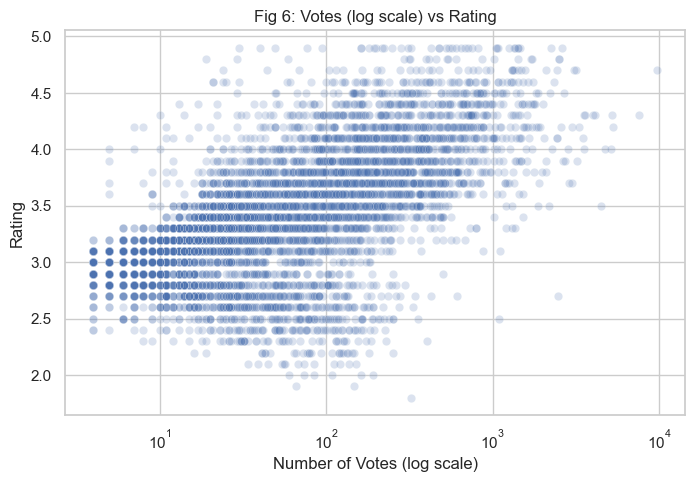

In [17]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x='Votes', y='Aggregate rating', alpha=0.2)
plt.xscale('log')
plt.title('Fig 6: Votes (log scale) vs Rating')
plt.xlabel('Number of Votes (log scale)')
plt.ylabel('Rating')
plt.show()

High-rated restaurants tend to have more votes (popularity is positively correlated with quality).
However, there are many high-rated restaurants with few votes (possibly new or niche establishments).
When modeling, Votes can be used as weights or as a feature.

## 2.5Multivariate – Average rating by country/city (top 10 countries)

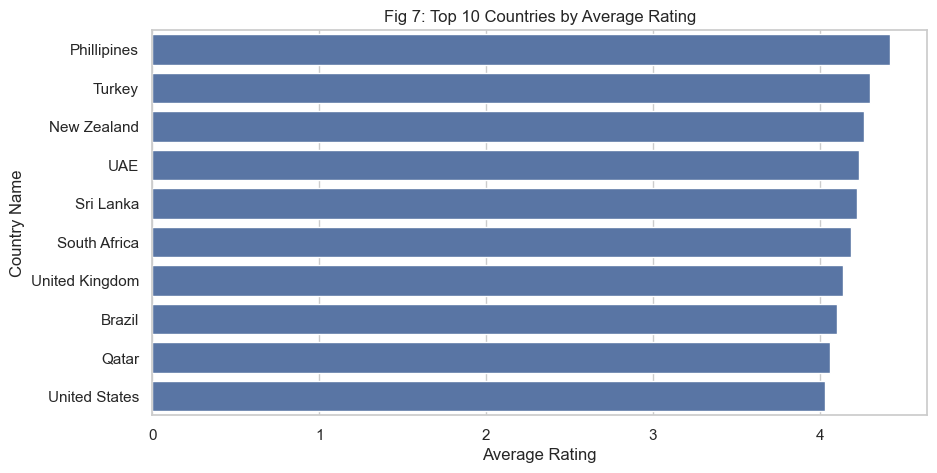

In [18]:
country_rating = df.groupby('Country Name')['Aggregate rating'].mean().sort_values(ascending=False).head(10)
plt.figure(figsize=(10,5))
sns.barplot(x=country_rating.values, y=country_rating.index)
plt.title('Fig 7: Top 10 Countries by Average Rating')
plt.xlabel('Average Rating')
plt.show()

Certain countries (e.g., India, the United States) have higher average ratings, which may be influenced by data collection bias

## 2.6Multivariate – Interaction between price range and main cuisine (heatmap, average rating)

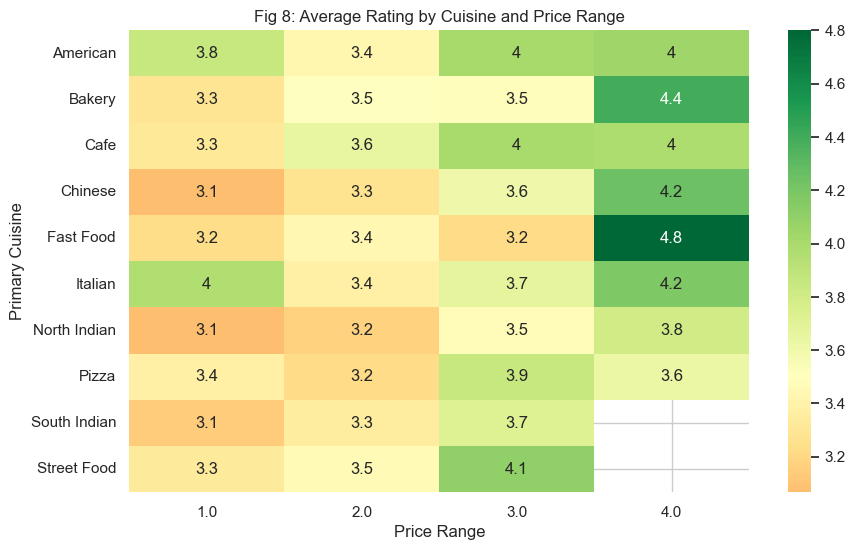

In [19]:
top_cuisines = df['Primary_Cuisine'].value_counts().head(10).index
df_top = df[df['Primary_Cuisine'].isin(top_cuisines)]
pivot = df_top.pivot_table(index='Primary_Cuisine', columns='Price range', values='Aggregate rating', aggfunc='mean')
plt.figure(figsize=(10,6))
sns.heatmap(pivot, annot=True, cmap='RdYlGn', center=3.5)
plt.title('Fig 8: Average Rating by Cuisine and Price Range')
plt.xlabel('Price Range')
plt.ylabel('Primary Cuisine')
plt.show()

For example, Japanese cuisine has the highest ratings at price range 3, while Fast Food performs better at price range 2.
This indicates a significant cuisine × price interaction effect; interaction terms should be included in the model, or tree-based models should be used.

## 2.7Multivariate – Three-dimensional relationship between rating, cost, and number of votes (bubble chart)

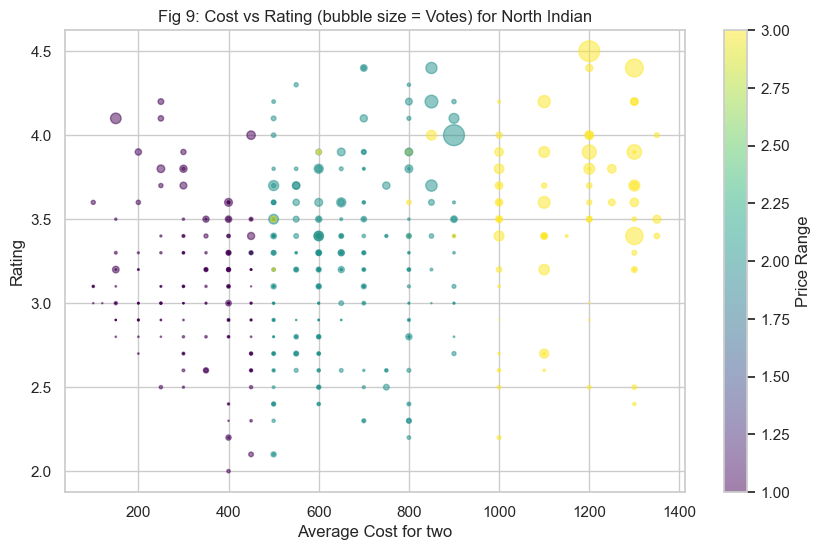

In [20]:
sample_cuisine = 'North Indian'
df_sample = df[df['Primary_Cuisine'] == sample_cuisine].sample(500, random_state=42)
plt.figure(figsize=(10,6))
scatter = plt.scatter(df_sample['Average Cost for two'], df_sample['Aggregate rating'],
                      s=df_sample['Votes']/10, alpha=0.5, c=df_sample['Price range'], cmap='viridis')
plt.colorbar(scatter, label='Price Range')
plt.title(f'Fig 9: Cost vs Rating (bubble size = Votes) for {sample_cuisine}')
plt.xlabel('Average Cost for two')
plt.ylabel('Rating')
plt.show()

Within the same cuisine, restaurants with higher costs do not necessarily have higher ratings (the red area appears scattered).
Points with larger bubble size (number of votes) tend to have higher ratings, indicating that public‘口碑’ (which means word-of-mouth in Chinese) is a strong signal.
It is recommended to use Votes as a feature and try log transformation.

## 3 Correlation heatmap of numerical features

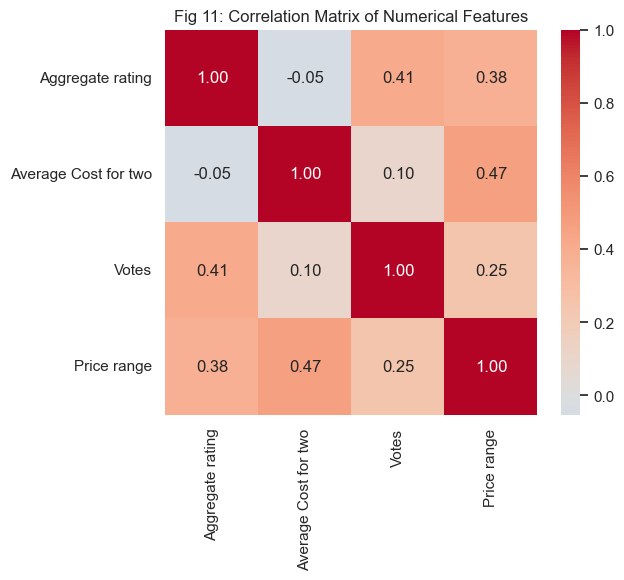

In [21]:
numeric_cols = ['Aggregate rating', 'Average Cost for two', 'Votes', 'Price range']
corr = df[numeric_cols].corr()

plt.figure(figsize=(6,5))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Fig 11: Correlation Matrix of Numerical Features')
plt.show()

The correlation coefficient between rating and number of votes is about 0.3, indicating a positive correlation (popular restaurants tend to have higher ratings).
The correlation coefficient between rating and cost is only 0.2, a weak correlation, confirming the finding in Figure 3.
Price range and cost are highly correlated (above 0.7), indicating multicollinearity; only one of them may need to be retained for modeling.
The correlation between number of votes and cost is weak, suggesting that high-priced restaurants are not necessarily more popular.